|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[1] Three tokenization schemes</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':300,
})

# **Part 1: Character-based tokenization**

In [3]:
# start with a text as one string variable
txt = 'The way you do anything is the way you do everything.'

# use list-comprehension to create a list of characters
characters = [c for c in txt]

# print the two versions
print('The full text:\n',txt,'\n')
print('As a list of characters:\n',characters,'\n')

# the vocab (unique elements)
char_vocab = list(sorted(set(characters)))
print('The vocabulary is:\n',char_vocab,'\n')

# print some numerical info
print(f'There are {len(characters)} characters, {len(char_vocab)} of which are unique.')

The full text:
 The way you do anything is the way you do everything. 

As a list of characters:
 ['T', 'h', 'e', ' ', 'w', 'a', 'y', ' ', 'y', 'o', 'u', ' ', 'd', 'o', ' ', 'a', 'n', 'y', 't', 'h', 'i', 'n', 'g', ' ', 'i', 's', ' ', 't', 'h', 'e', ' ', 'w', 'a', 'y', ' ', 'y', 'o', 'u', ' ', 'd', 'o', ' ', 'e', 'v', 'e', 'r', 'y', 't', 'h', 'i', 'n', 'g', '.'] 

The vocabulary is:
 [' ', '.', 'T', 'a', 'd', 'e', 'g', 'h', 'i', 'n', 'o', 'r', 's', 't', 'u', 'v', 'w', 'y'] 

There are 53 characters, 18 of which are unique.


In [7]:
# the tokens and their indices

# vertical format
# for index,tok in enumerate(char_vocab):
#   print(f'Index {index:2} is "{tok}"')

# horizontal format is better for the book figure ;)

for i in range(len(char_vocab)):
  print(f'Token: {char_vocab[i]} - Index: [{i}] \n')

# print('Token :',end='')
# for v in char_vocab:
#   print(f' "{v}" | ', end='')
# print('\n','-'*131)

# print('Index :',end='')
# [print(f' {i:2}  | ',end='') for i in range(len(char_vocab))];

Token:   - Index: [0] 

Token: . - Index: [1] 

Token: T - Index: [2] 

Token: a - Index: [3] 

Token: d - Index: [4] 

Token: e - Index: [5] 

Token: g - Index: [6] 

Token: h - Index: [7] 

Token: i - Index: [8] 

Token: n - Index: [9] 

Token: o - Index: [10] 

Token: r - Index: [11] 

Token: s - Index: [12] 

Token: t - Index: [13] 

Token: u - Index: [14] 

Token: v - Index: [15] 

Token: w - Index: [16] 

Token: y - Index: [17] 



In [20]:
# initialize a list
tokens = [0]*len(txt)

# loop through text, find the indices into the vocab
# this is called encoding
for i,c in enumerate(txt):
  tokens[i] = char_vocab.index(c)

print(tokens)

[2, 7, 5, 0, 16, 3, 17, 0, 17, 10, 14, 0, 4, 10, 0, 3, 9, 17, 13, 7, 8, 9, 6, 0, 8, 12, 0, 13, 7, 5, 0, 16, 3, 17, 0, 17, 10, 14, 0, 4, 10, 0, 5, 15, 5, 11, 17, 13, 7, 8, 9, 6, 1]


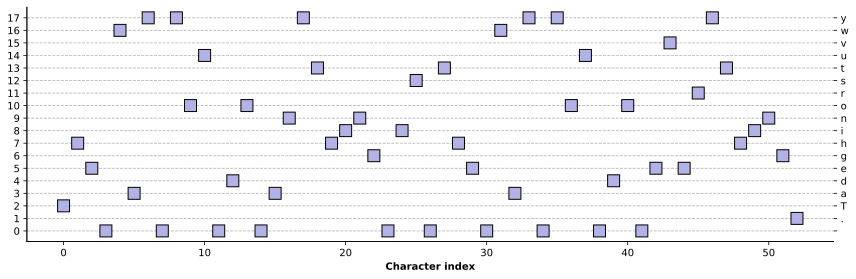

In [21]:
# create a figure
_,ax = plt.subplots(1,figsize=(12,4))

# plot the tokens
ax.plot(tokens,'ks',markersize=12,markerfacecolor=[.7,.7,.9])
ax.set(xlabel='Character index',yticks=range(len(char_vocab)))
ax.grid(linestyle='--',axis='y')

# invisible axis for right-hand-side labels
ax2 = ax.twinx()
ax2.plot(tokens,alpha=0)
ax2.set(yticks=range(len(char_vocab)),yticklabels=char_vocab)

plt.tight_layout()
plt.savefig('ch2_proj1_part1-tokenscatter.png')
plt.show()

# **Part 2: Word-based tokenization**

In [22]:
# split into words
words = txt.split()

# print the words
print('The list of words is:\n',words,'\n')

# find the unique words, and print numerical info
word_vocab = list(sorted(set(words)))
print(f'There are {len(words)} words, {len(word_vocab)} of which are unique.\n')

print('The vocab is:\n',word_vocab)

The list of words is:
 ['The', 'way', 'you', 'do', 'anything', 'is', 'the', 'way', 'you', 'do', 'everything.'] 

There are 11 words, 8 of which are unique.

The vocab is:
 ['The', 'anything', 'do', 'everything.', 'is', 'the', 'way', 'you']


In [23]:
# initialize a list
tokens = [0]*len(words)

# loop through text, find the indices into the vocab
for i,c in enumerate(words):
  tokens[i] = word_vocab.index(c)

print(tokens)

[0, 6, 7, 2, 1, 4, 5, 6, 7, 2, 3]


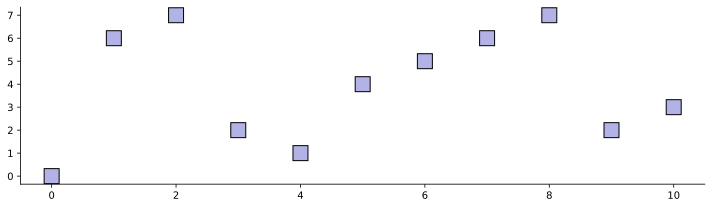

In [24]:
# create a figure
_,ax = plt.subplots(1,figsize=(10,3))

# plot the tokens
ax.plot(tokens,'ks',markersize=15,markerfacecolor=[.7,.7,.9])

# invisible axis for right-hand-side labels

plt.tight_layout()
plt.savefig('ch2_proj1_part2.png')
plt.show()

# **Part 3: OpenAI's GPT2 tokenizer**

In [27]:
# GPT2 tokenizer
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained('gpt2')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

c:\Users\daler\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\daler\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [28]:
tokenizer.vocab_size

50257

In [29]:
gpt2_tokens = tokenizer.encode(txt)

for token in gpt2_tokens:
  print(f'Token {token:4} is "{tokenizer.decode([token])}"')

Token  464 is "The"
Token  835 is " way"
Token  345 is " you"
Token  466 is " do"
Token 1997 is " anything"
Token  318 is " is"
Token  262 is " the"
Token  835 is " way"
Token  345 is " you"
Token  466 is " do"
Token 2279 is " everything"
Token   13 is "."


In [30]:
# leading spaces
word1 = ' Mike'
word2 = 'Mike'

for w in [word1,word2]:
  print(f'Token for "{w}" is {tokenizer.encode(w)}')

Token for " Mike" is [4995]
Token for "Mike" is [16073]


In [31]:
print(f'There are {len(gpt2_tokens)} tokens, {len(set(gpt2_tokens))} of which are unique.')

There are 12 tokens, 9 of which are unique.


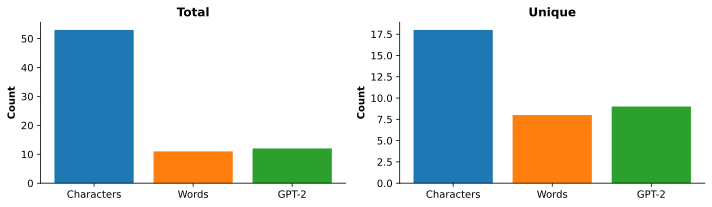

In [32]:
_,axs = plt.subplots(1,2,figsize=(10,3))

# bars of total counts
axs[0].bar(0,len(characters))
axs[0].bar(1,len(words))
axs[0].bar(2,len(gpt2_tokens))
axs[0].set(xticks=[0,1,2],xticklabels=['Characters','Words','GPT-2'],
           ylabel='Count',title='Total')

# bars of unique counts
axs[1].bar(0,len(char_vocab))
axs[1].bar(1,len(word_vocab))
axs[1].bar(2,len(set(gpt2_tokens)))
axs[1].set(xticks=[0,1,2],xticklabels=['Characters','Words','GPT-2'],
           ylabel='Count',title='Unique')

plt.tight_layout()
plt.savefig('ch2_proj1_part3.png')
plt.show()